# 01 · 20 个真实 FER 数据集：主要统计实验复现

本 Notebook 对正文四个研究问题逐项给出证据：表征指标是否冗余、全局指标是否一致、局部指标是否一致，以及不同数据源的偏差分布。

数据源是作者公开且固定 commit 的 20 个完整匿名统计 CSV。单一组件计算与作者逐值交叉验证；图形重绘使用独立实现。所有图和明细均导出到 `results/`，不依赖联网。

In [1]:
from pathlib import Path
import os, sys, json, warnings, time
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd() if (Path.cwd()/"pyproject.toml").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT/"src"))
from experiments import *
warnings.filterwarnings("ignore", category=FutureWarning)
print("项目目录:", ROOT)
print("Python:", sys.version.split()[0], "NumPy:", np.__version__, "Pandas:", pd.__version__)


项目目录: /workspace
Python: 3.11.15 NumPy: 1.26.4 Pandas: 2.1.4


In [2]:
start = time.perf_counter()
data = load_data()
provenance_info = provenance(data)
rep, glob, loc, checks = main_metrics(data)
print(f"真实记录数: {sum(map(len,data.values())):,}; 数据集: {len(data)}")
print("与作者独立交叉验证项数:", len(checks), "全部通过:", checks.match.all())
assert checks.match.all()
display(pd.read_csv(ROOT/'results/tables/inventory.csv'))
display(rep.head())

/workspace/src/experiments.py:77: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho=spearmanr(npmi.ravel(),z.ravel()).statistic
/workspace/src/experiments.py:82: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  stable_rho=spearmanr(npmi.round(12).ravel(),z.round(12).ravel()).statistic if min(table.shape)>1 else np.nan
/workspace/src/experiments.py:77: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho=spearmanr(npmi.ravel(),z.ravel()).statistic
/workspace/src/experiments.py:82: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  stable_rho=spearmanr(npmi.round(12).ravel(),z.round(12).ravel()).statistic if min(table.shape)>1 else np.nan
/workspace/src/experiments.py:77: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho=spearmanr(npmi.ravel(),z.ravel()

真实记录数: 794,166; 数据集: 20
与作者独立交叉验证项数: 1280 全部通过: True


/workspace/src/experiments.py:77: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho=spearmanr(npmi.ravel(),z.ravel()).statistic
/workspace/src/experiments.py:82: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  stable_rho=spearmanr(npmi.round(12).ravel(),z.round(12).ravel()).statistic if min(table.shape)>1 else np.nan
/workspace/src/experiments.py:77: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho=spearmanr(npmi.ravel(),z.ravel()).statistic
/workspace/src/experiments.py:81: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  raw_rho=spearmanr(up_nm,up_z).statistic if min(table.shape)>1 else np.nan
/workspace/src/experiments.py:82: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  stable_rho=spearmanr(npmi.round(12).ravel(),z.round(12).ravel()).statis

,dataset,n,collection,age_groups,race_groups,gender_groups,label_groups
0,adfes,132,LAB,2,3,2,6
1,affectnet,286341,ITW-I,9,7,2,7
2,caer-s,69757,ITW-M,9,7,2,7
3,ck+,3607,LAB,4,7,2,7
4,ck,2820,LAB,3,6,2,7
5,expw,83208,ITW-I,9,7,2,7
6,fer2013,33113,ITW-I,9,7,2,7
7,ferplus,32673,ITW-I,9,7,2,7
8,gemep,2913,LAB,5,1,2,6
9,isafe,26916,LAB,3,3,2,7


,dataset,component,R,ENS,D,1/D,1-D,H,SEI,NSD,IR,BP
0,adfes,age,2,1.356131,0.834711,1.198020,0.165289,0.304636,0.439497,0.818182,10.00000,0.909091
1,adfes,race,3,2.478207,0.471074,2.122807,0.528926,0.907535,0.826074,0.454545,3.50000,0.636364
2,adfes,gender,2,1.926070,0.537190,1.861538,0.462810,0.655482,0.945660,0.272727,1.75000,0.636364
3,adfes,label,6,6.000000,0.166667,6.000000,0.833333,1.791759,1.000000,0.000000,1.00000,0.166667
4,affectnet,age,9,5.851302,0.234444,4.265412,0.765556,1.766664,0.804043,0.372491,34.70342,0.411097


## RQ1 / Fig.2–3：表征指标的排序一致性

论文先在 age、race、gender、label **分别**跨 20 个数据集计算 Spearman 相关矩阵，再逐单元平均，不能把 80 行混在一起做相关。D/NSD/BP 转为补数、IR 转为倒数，确保排序方向一致。组件内部先成对删除 NaN；复现图中将不可定义的相关填 0 再对四组件平均。该约定能复现印刷数值，但 0 不表示真实无相关。若改为仅平均可定义组件，R/1-NSD 为 0.0441 而非 0.0331，R/SEI 为 −0.0958 而非 −0.0718，展示聚合约定的敏感性。图中展示原始数值；配色尺度与论文可以不同。

待检验：ENS 与 H 完全单调等价；SEI 与 1-NSD 高相关；R 与 IR 的行为不同。

,R,1/IR,1-NSD,SEI,ENS,H,1-BP,1/D,1-D
R,1.000,-0.499,0.033,-0.072,0.571,0.571,0.363,0.456,0.456
1/IR,-0.499,1.000,0.623,0.748,0.171,0.171,0.245,0.245,0.245
1-NSD,0.033,0.623,1.000,0.961,0.788,0.788,0.939,0.925,0.925
SEI,-0.072,0.748,0.961,1.000,0.706,0.706,0.841,0.839,0.839
ENS,0.571,0.171,0.788,0.706,1.000,1.000,0.887,0.955,0.955
H,0.571,0.171,0.788,0.706,1.000,1.000,0.887,0.955,0.955
1-BP,0.363,0.245,0.939,0.841,0.887,0.887,1.000,0.967,0.967
1/D,0.456,0.245,0.925,0.839,0.955,0.955,0.967,1.000,1.000
1-D,0.456,0.245,0.925,0.839,0.955,0.955,0.967,1.000,1.000


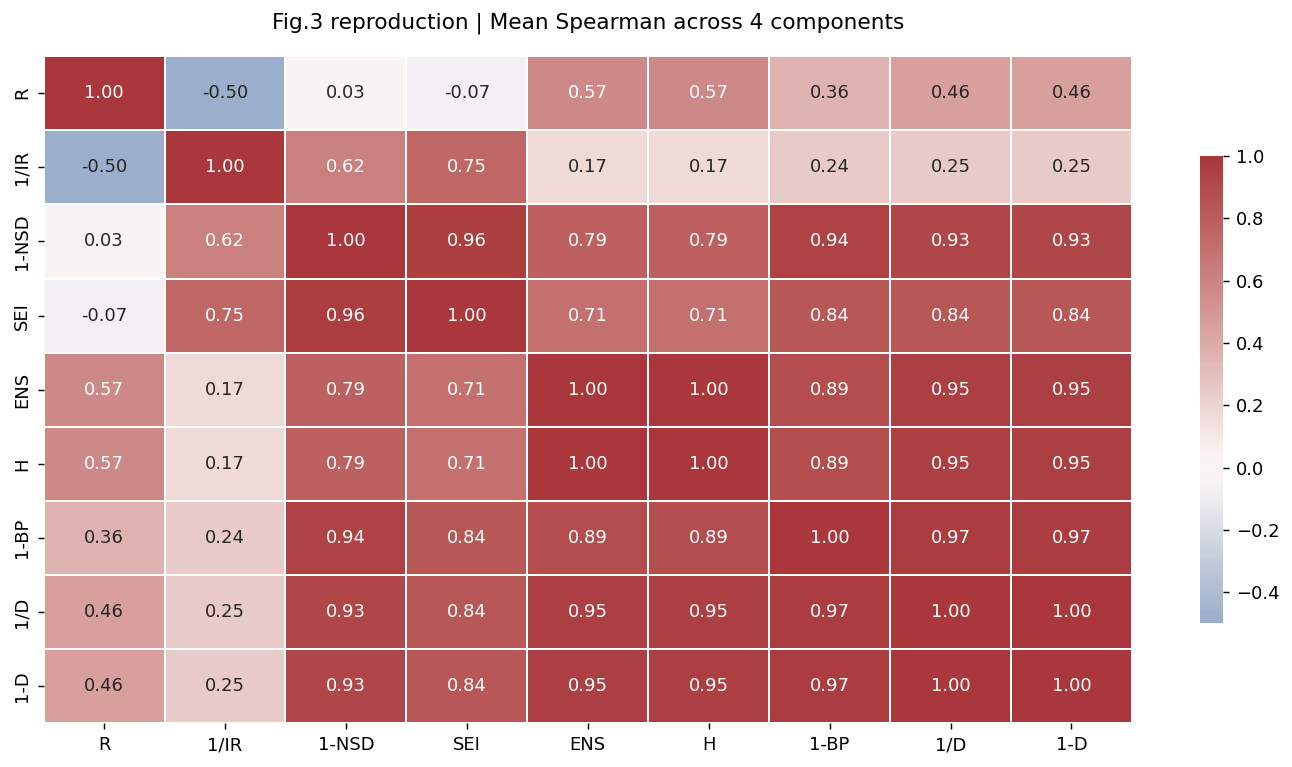

SEI 与 1-NSD: 0.9610336499242507


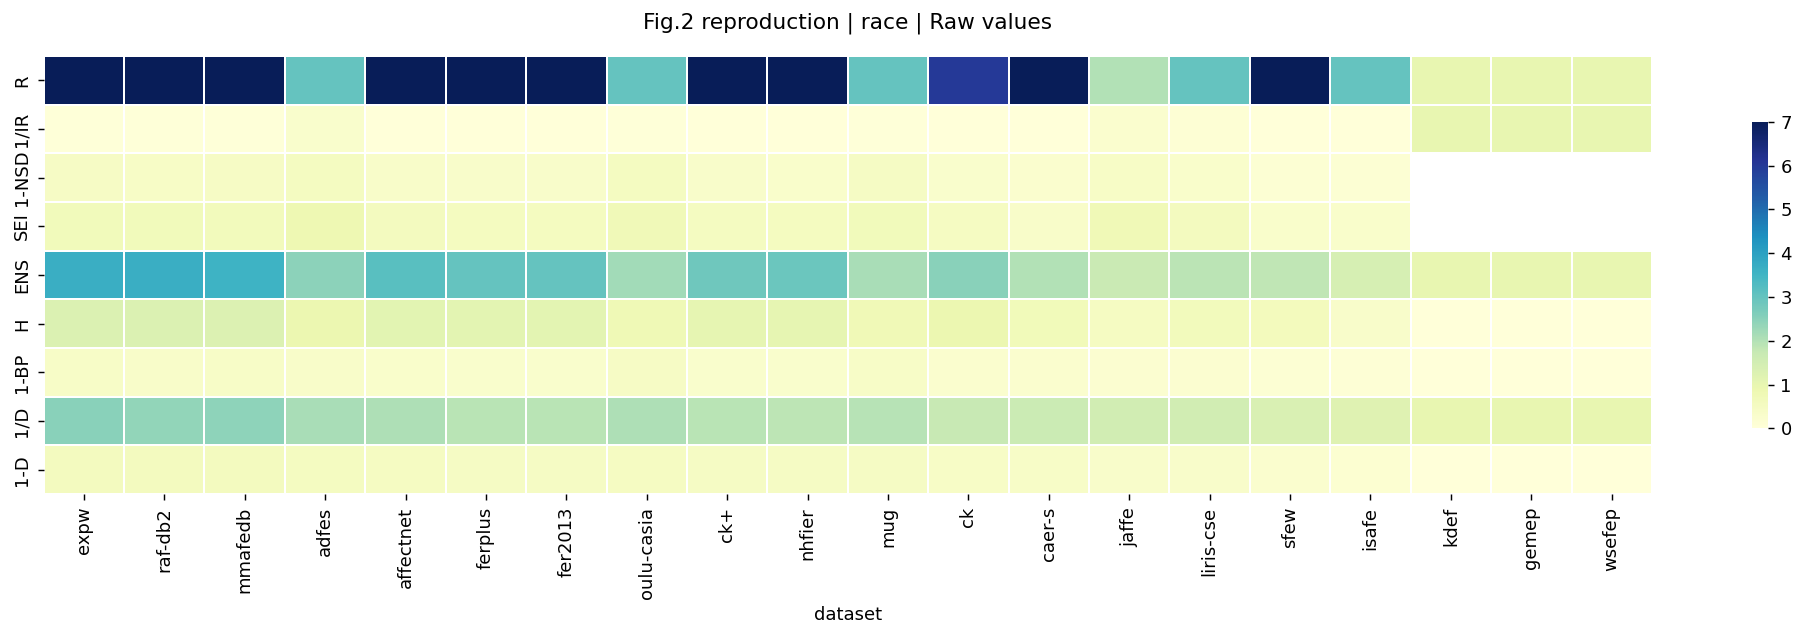

In [3]:
rcor, gcor = agreement(rep, glob)
display(rcor.round(3))
display(Image(filename=str(ROOT/'results/figures/fig03_agreement.png')))
assert np.isclose(rcor.loc['ENS','H'], 1)
print("SEI 与 1-NSD:", rcor.loc['SEI','1-NSD'])
display(Image(filename=str(ROOT/'results/figures/fig02_race.png')))

## RQ2 / Fig.4–5：全局刻板偏差指标

每个指标衡量“人口属性与表情标签的统计依赖”，不是模型精度。由于标签分布和变量类别数不同，量纲或区间接近也不意味着可直接互换数值。

图中 Ux=I/H(G)，Uy=I/H(Y)。按论文 Eq.(13) 的分母，UR 对应 Ux、U 对应 Uy；作者函数 theilsu(x,y) 的命名方向与正文不一致。

论文建议 Cramér V：直观且不要求两个变量类别数相同。论文的经验强度阈值不是经过多重比较校正的显著性检验，演示中只称其为描述性参考。

,V,Ux,T,NMI,C,Uy
V,1.000,0.982,0.981,0.945,0.940,0.928
Ux,0.982,1.000,0.970,0.943,0.921,0.912
T,0.981,0.970,1.000,0.975,0.978,0.965
NMI,0.945,0.943,0.975,1.000,0.983,0.992
C,0.940,0.921,0.978,0.983,1.000,0.988
Uy,0.928,0.912,0.965,0.992,0.988,1.000


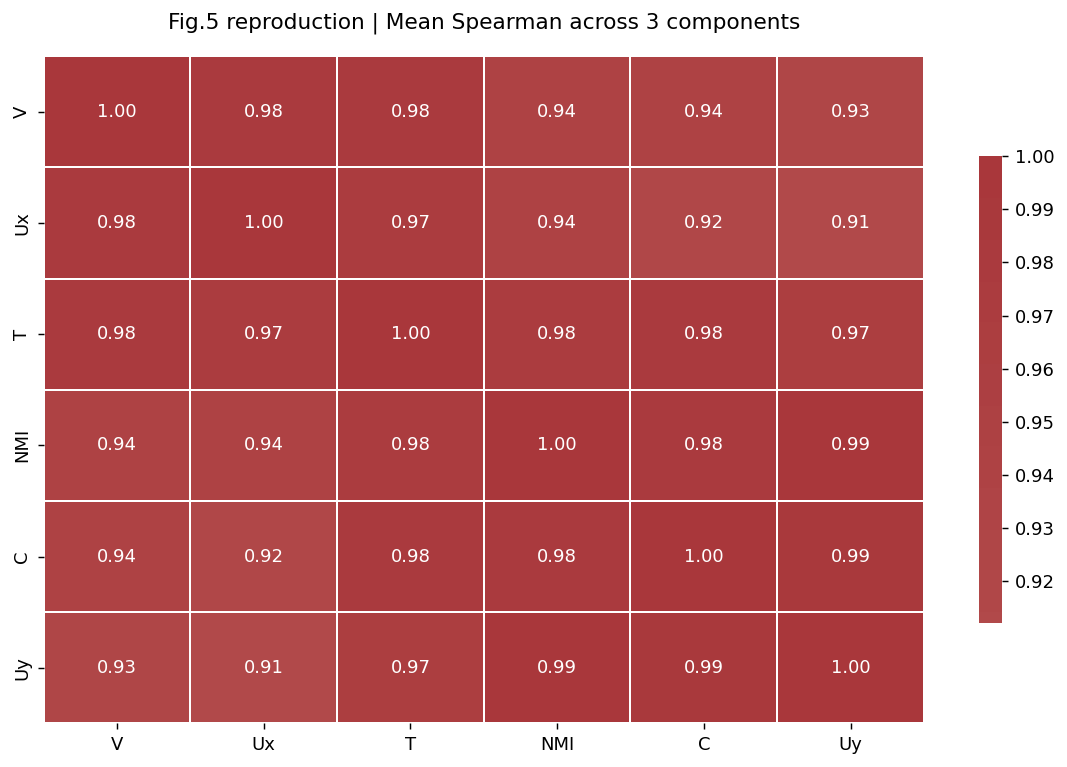

全局指标非对角相关最小值: 0.9121234642063162


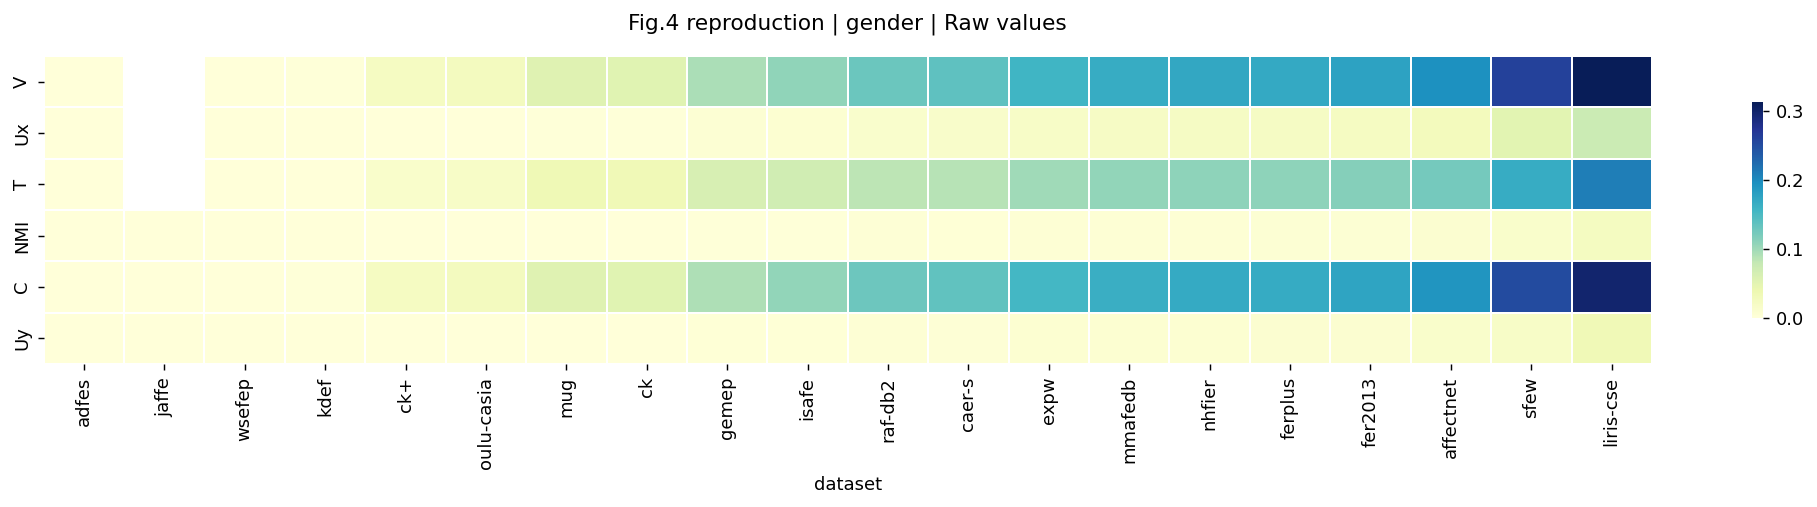

In [4]:
display(gcor.round(3))
display(Image(filename=str(ROOT/'results/figures/fig05_agreement.png')))
print("全局指标非对角相关最小值:", gcor.where(~np.eye(len(gcor),dtype=bool)).min().min())
display(Image(filename=str(ROOT/'results/figures/fig04_gender.png')))

## RQ3 / Fig.6 与附录 B：局部刻板偏差

对每个数据集、每个组件生成 count/NPMI/Z 的完整矩阵，展平成同一顺序计算 Spearman，随后平均。保留联合概率为零但边缘非零的单元：NPMI=-1，而不是删掉。只有一个组时关联无法识别，相关系数记为 NaN。

论文报告均值 ρ=0.96±0.02。我们同时导出有效组合数、均值和标准差；这不是对不同数据集“人类总体”的置信区间。作者浮点原始值在完全独立表中可能产生仅 1e-16 的伪排序，因此同时报告原始作者相关与 12 位舍入后的并列稳健相关。

有效数据集×组件: 50 / 60
独立公式：局部相关均值: 0.9540580281350673 样本标准差: 0.03944699487134505 总体标准差: 0.039050532599342665
原始作者浮点计算: 0.9574592393353951 0.03945626181890807
将 1e-12 以下差异视为并列后: 0.954057487618792 0.03905065613560056


component,age,gender,race
dataset,,,
adfes,NaN,NaN,NaN
affectnet,0.9583,0.9824,0.9312
caer-s,0.9872,0.9604,0.9609
ck,0.8844,0.9780,0.9323
ck+,0.9196,0.9648,0.9534
expw,0.9683,0.9604,0.9695
fer2013,0.9898,0.9912,0.9537
ferplus,0.9789,0.9604,0.9331
gemep,0.9853,0.9860,NaN


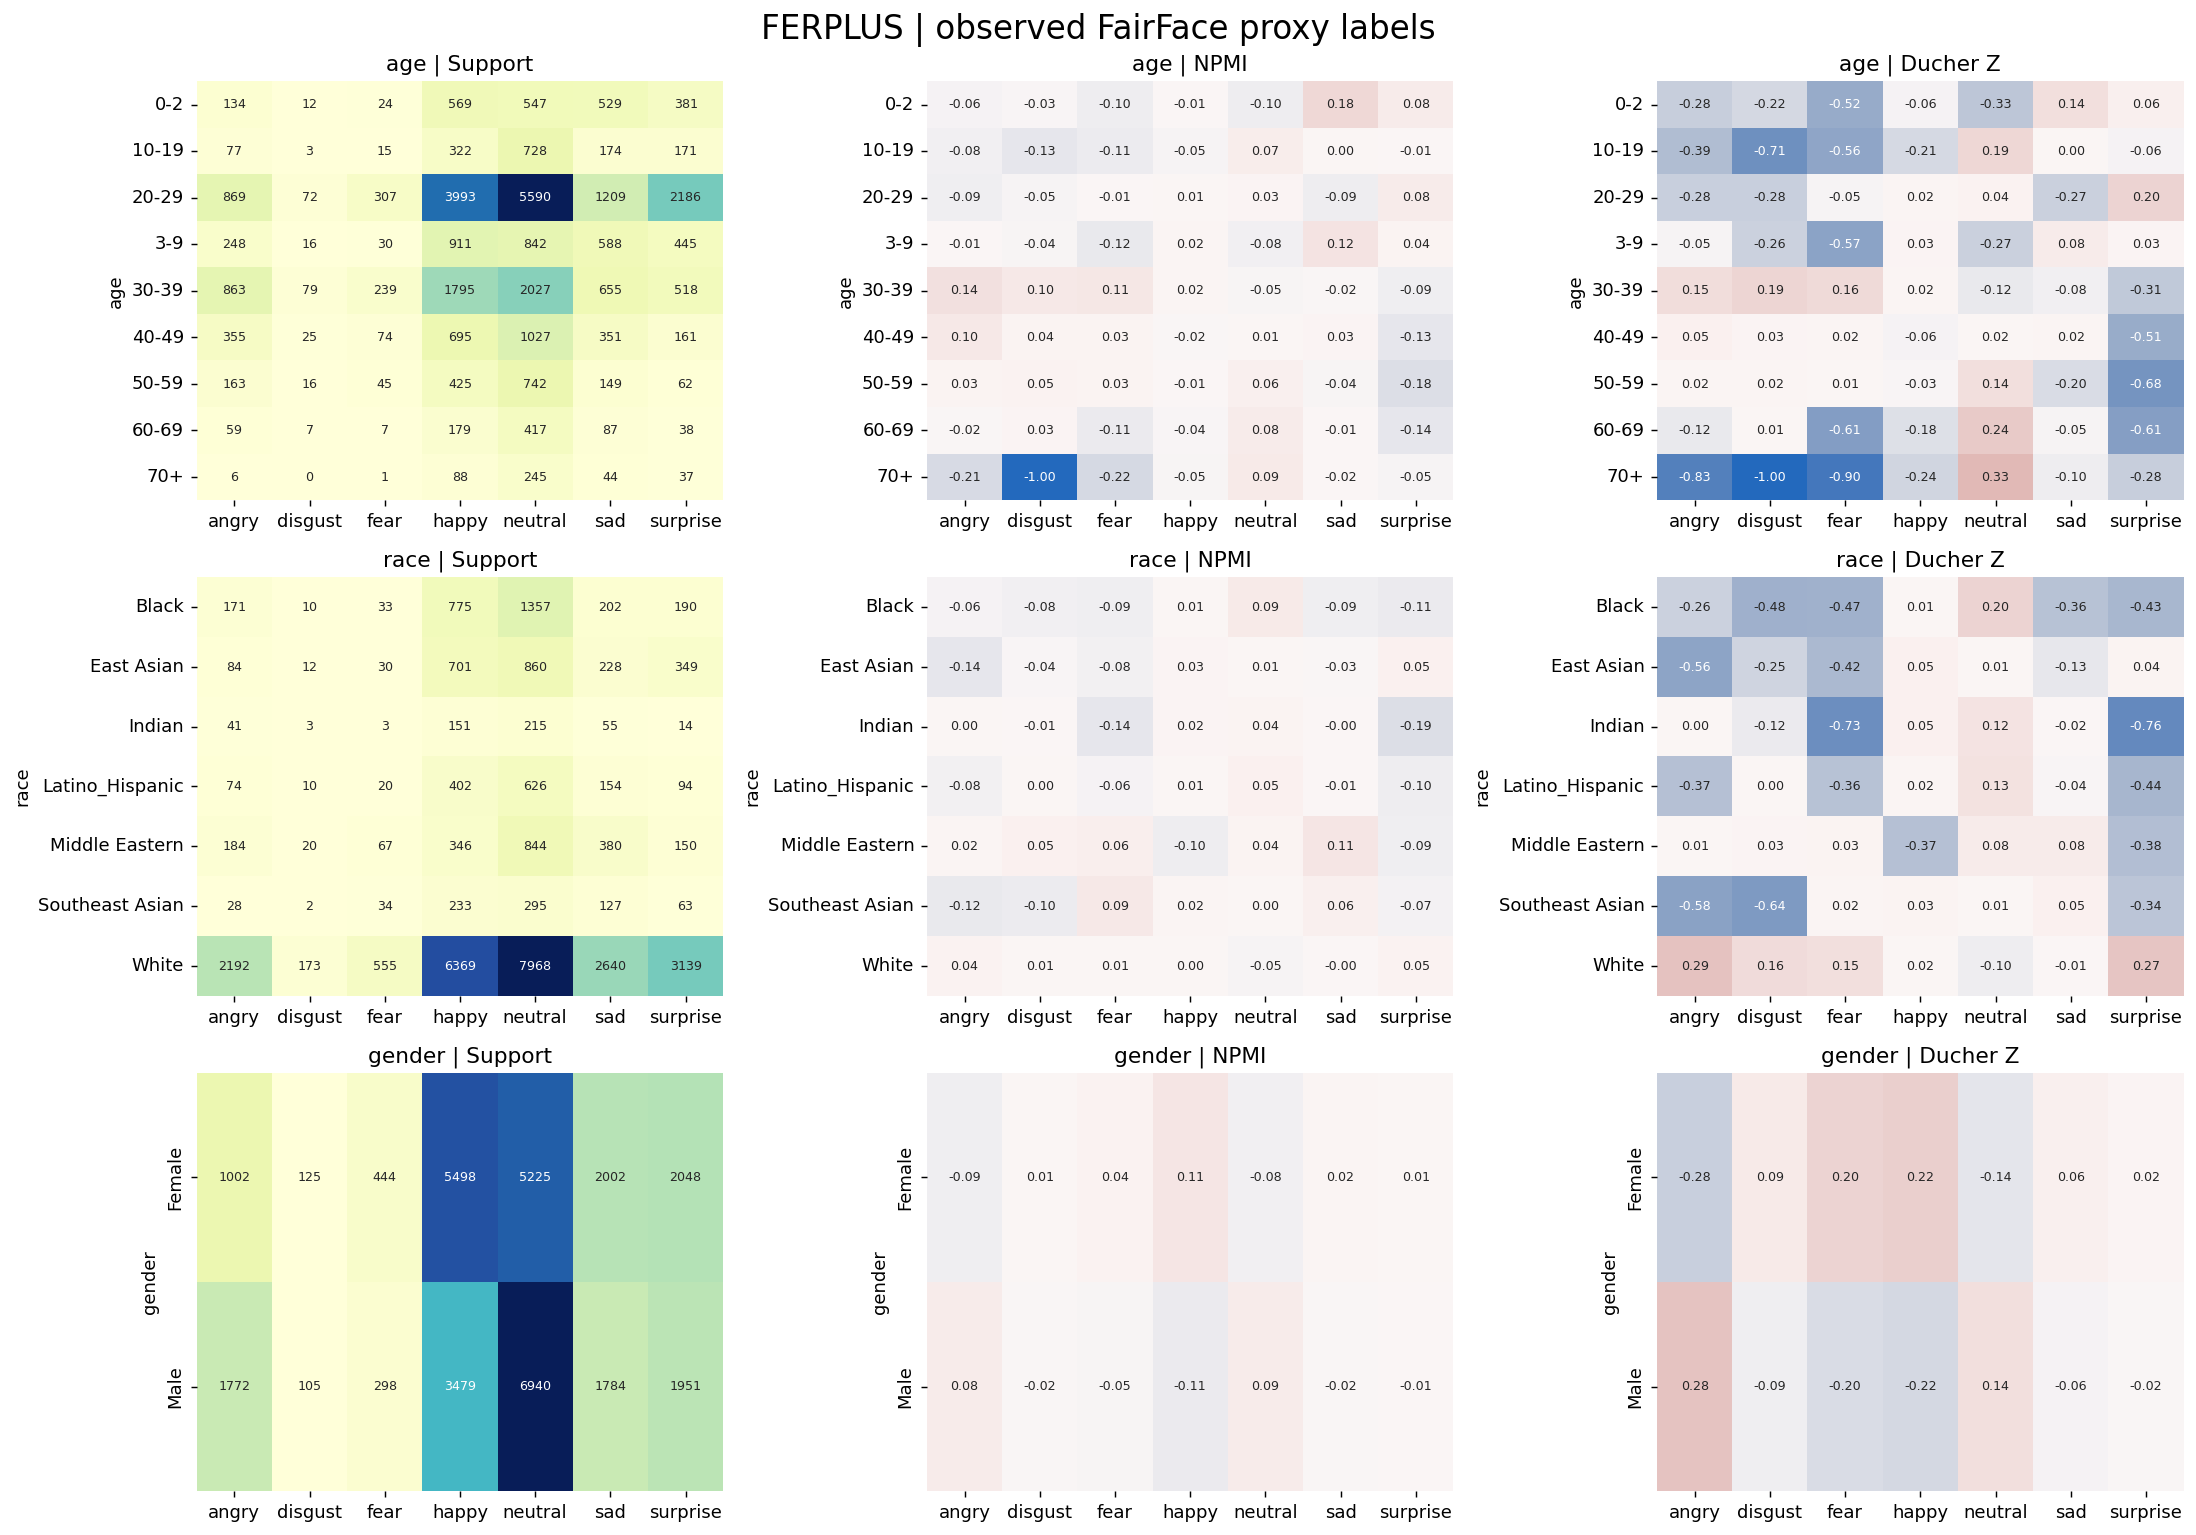

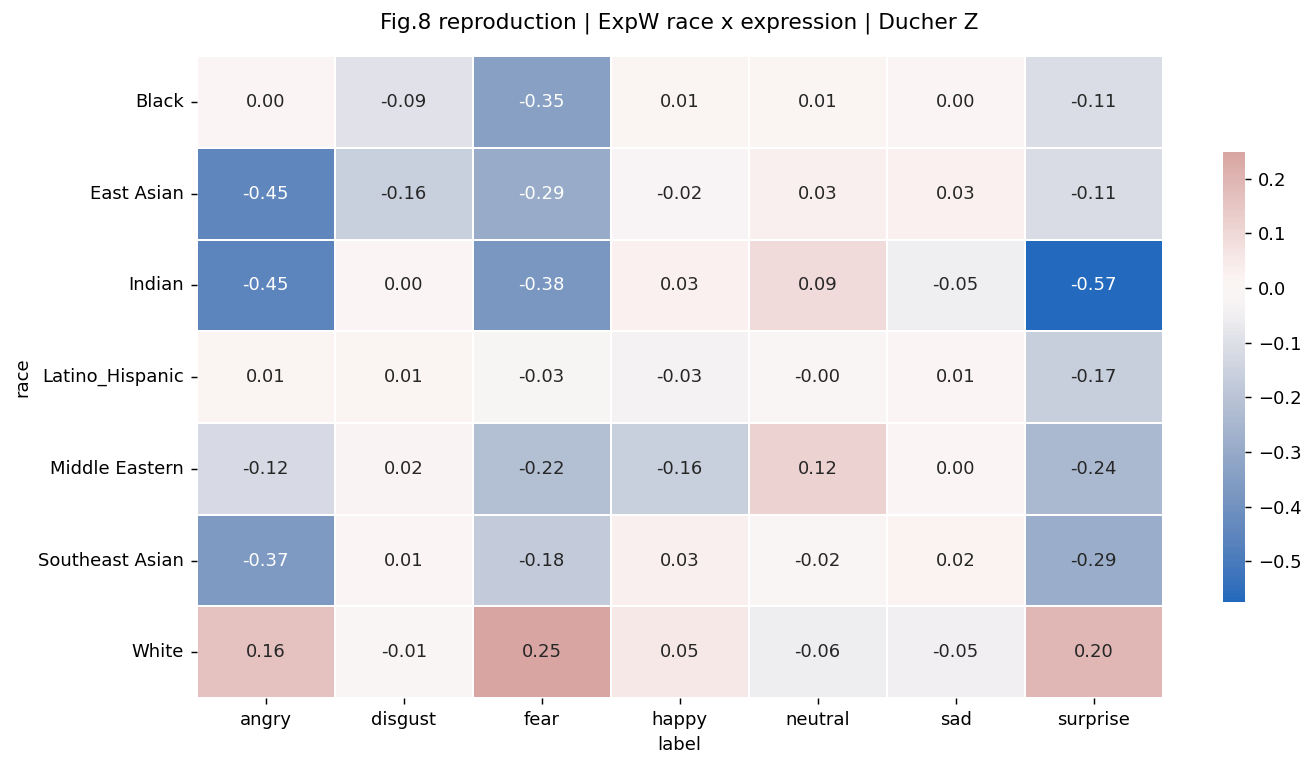

In [5]:
local_plots(data)
valid = loc.rho.dropna()
print("有效数据集×组件:", len(valid), "/", len(loc))
print("独立公式：局部相关均值:", valid.mean(), "样本标准差:", valid.std(ddof=1), "总体标准差:", valid.std(ddof=0))
print("原始作者浮点计算:", loc.upstream_raw_rho.mean(), loc.upstream_raw_rho.std(ddof=0))
print("将 1e-12 以下差异视为并列后:", loc.tie_stabilized_rho.mean(), loc.tie_stabilized_rho.std(ddof=0))
display(loc.pivot(index='dataset',columns='component',values='rho').round(4))
display(Image(filename=str(ROOT/'results/figures/fig06_ferplus.png')))
display(Image(filename=str(ROOT/'results/figures/fig08_expw.png')))

## RQ4 / Fig.7–8：按数据来源比较偏差

LAB=实验室；ITW-M=影视；ITW-I=互联网查询。固定年龄/种族/性别标签空间分别为 9/7/2。`K-ENS` 同时反映缺失与不均衡；`1-SEI` 仅反映已出现组的不均衡。

这里比较的是数据集集合的描述性结果。不能解释为“互联网收集必然更公平”的因果结论。

ENS_over_K    SEI
collection component                   
ITW-I      age             0.630  0.789
           gender          0.997  0.996
           race            0.468  0.607
ITW-M      age             0.383  0.563
           gender          0.963  0.945
           race            0.276  0.337
LAB        age             0.215  0.591
           gender          0.931  0.961
           race            0.262  0.616

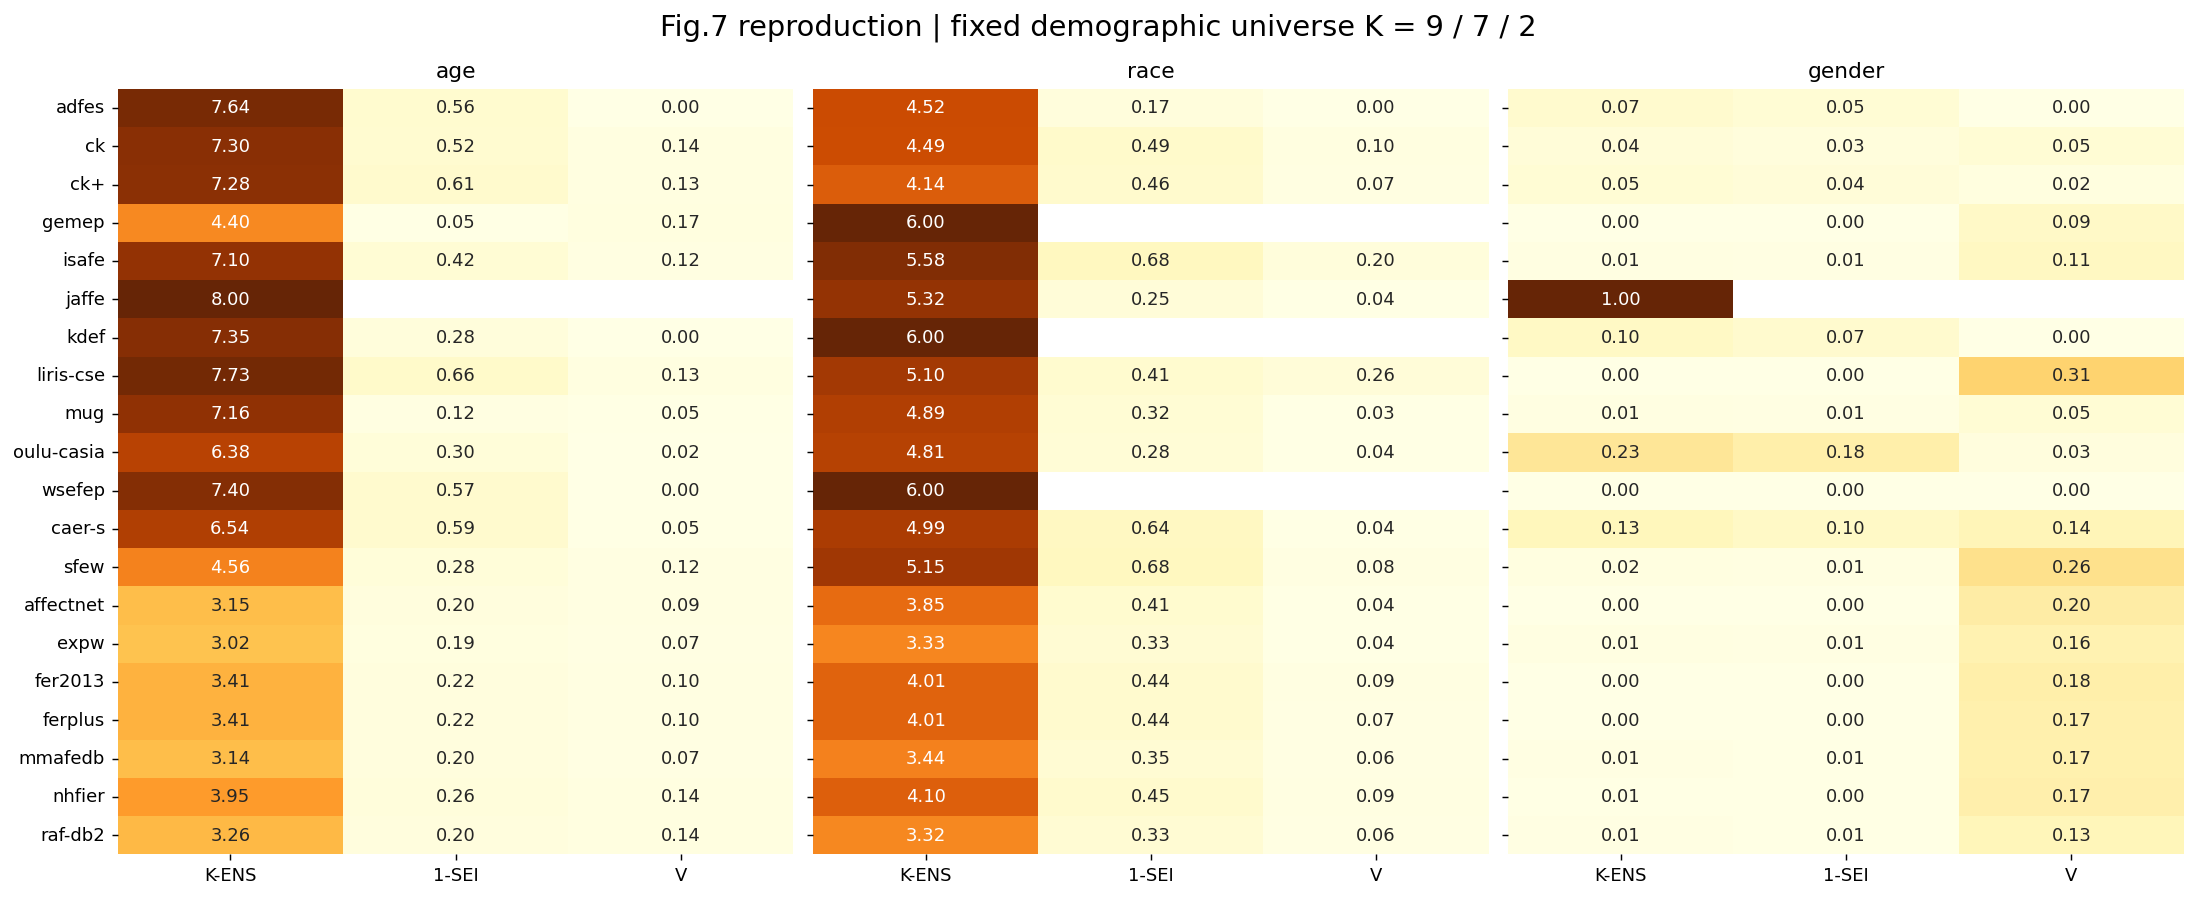

ADFES race ENS 2.4782069486465024 PASS
ExpW race V 0.04104288518527492 PASS


In [6]:
summary_plot(rep,glob)
inv=pd.read_csv(ROOT/'results/tables/inventory.csv')
summary=rep[rep.component.isin(COMPONENTS)].merge(inv[['dataset','collection']],on='dataset')
summary['ENS_over_K']=summary.apply(lambda r:r.ENS/UNIVERSE[r.component],axis=1)
display(summary.groupby(['collection','component'])[['ENS_over_K','SEI']].mean().round(3))
display(Image(filename=str(ROOT/'results/figures/fig07_summary.png')))
# 上游 README 提供的未四舍五入锚点，比只看趋势更严格。
anchors=[('ADFES race ENS', rep.query("dataset=='adfes' and component=='race'").ENS.iloc[0],2.478206948646503),
         ('ExpW race V', glob.query("dataset=='expw' and component=='race'").V.iloc[0],0.04104288518527493)]
for name,actual,expected in anchors:
    assert np.isclose(actual,expected,atol=1e-12), (name,actual,expected)
    print(name, actual, 'PASS')

## 附录 A：四种受控偏差的列联表与指标曲线

重建 Table III–VI：全局性别比例、仅 happy 类、happy/angry 反向、happy/angry 同向偏差；比例 0–1、步长 0.1。遵循表格整数取整，balanced 时每类男女分别 floor(n_y/2)，因此样本总数与极端设置可相差几个样本。

**重要差异**：原文 Experiment 1 文字将单组端点的 V 描述为 0，但公式与 SciPy 在维度退化时 V 未定义。图中保留 NaN 空点，不假装测到了零。Table III–VI 的端点与中点计数另导出，便于逐格核对。

只复现 Fig.9–12(a)；(b)(c) recall 曲线依赖原图和预训练网络，本交付未执行。

,experiment,fraction,ENS,SEI,V
5,1,0.5,2.0,1.0,0.0
16,2,0.5,2.0,1.0,0.0
27,3,0.5,2.0,1.0,0.0
38,4,0.5,2.0,1.0,0.0


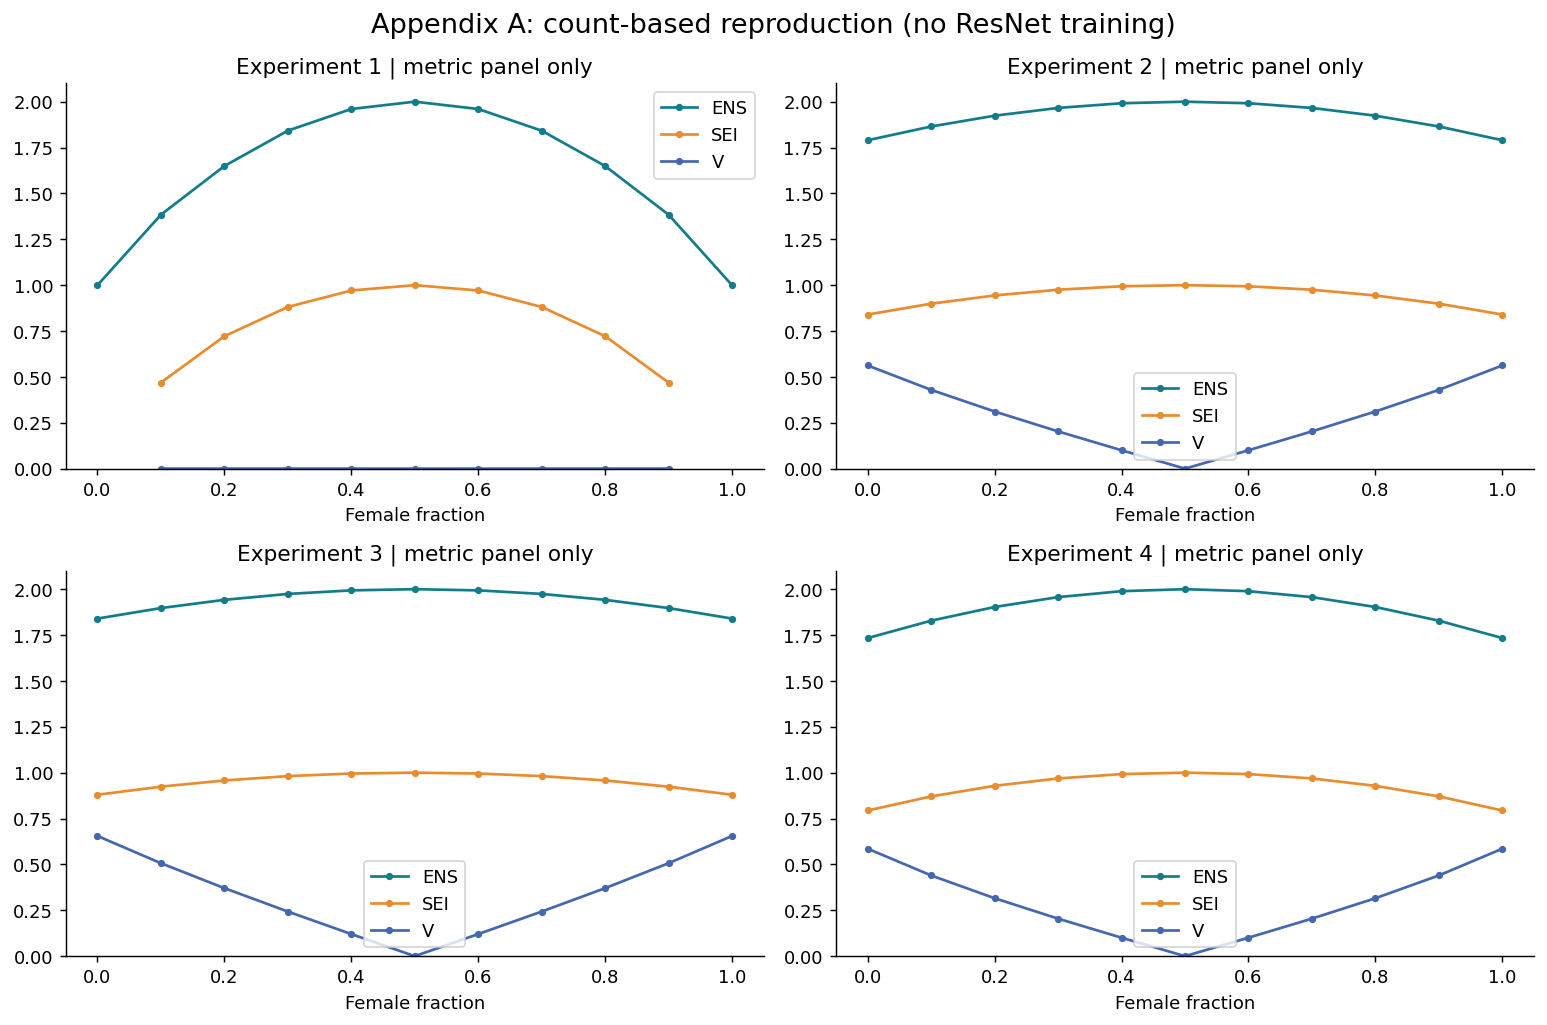

本 Notebook 执行秒数: 26.39


In [7]:
appendix = appendix_curves()
display(appendix.query('fraction==0.5'))
display(Image(filename=str(ROOT/'results/figures/appendixA_curves.png')))
print("本 Notebook 执行秒数:", round(time.perf_counter()-start,2))

## 结果判定

精确比对：所有单组件指标与固定上游作者实现一致，README 的两个未四舍五入数值锚点通过。论文图的数值/相关系数另在 `results/tables/paper_comparison.csv` 中逐项比对，保留任何不吻合项及可能原因，不能用“源码一致”替代“论文一致”。

本地输出包括：20 个数据集全量表征和全局指标、60 套局部矩阵、正文重绘、附录 B 的 20 幅矩阵总览、附录 A 的四种指标曲线。